<p style="text-align: center; font-size: 32px; font-weight: bold;"><u>Vortex Panel Method</u></p>
<h3 align="left">Anchal Bhupal</h3>
<h3 align="left">SC26M006</h3>
<p align="left">AE 611 &ndash; Assignment on the 2D Vortex Panel Method</p>

# 1. Vortex Panel Methods
## 1.1 Aim:
This assignment aims to implement and study two-dimensional vortex panel methods for predicting the aerodynamic characteristics of a circular cylinder and airfoils.
The main objectives are: \
1. To develop algorithms for the constant-strength and linear-strength vortex panel methods.
2. To implement the algorithms in Python as `vortex_panel_method_0()` and `vortex_panel_method_1()`.
3. To verify the implementations against the exact pressure distribution around a circular cylinder and study convergence.
4. To verify them on a symmetric (NACA0012) and a cambered (NACA4412) airfoil, and to investigate convergence with the number of panels and with the distribution of panel lengths.
5. To predict the aerodynamic characteristics ($C_l$) and the pressure-coefficient distributions of one symmetric and one cambered airfoil.
6. To show how increasing airfoil thickness reduces the predictive capability of the method, and so identify the limitations of panel methods.

The study helps clarify how surface discretisation affects the numerical solution, how the choice of vortex-strength representation influences it, and where the inviscid model stops being a reliable predictor.

## 1.2 Introduction to Vortex Panel Method
A panel method estimates the flow around a body by representing its surface as a collection of small straight-line segments called panels. Instead of solving the flow equations at every point in the fluid domain, the flow is represented by mathematical singularities (sources, doublets, or vortices) distributed along the body surface, so only the surface needs to be discretised _(Katz and Plotkin, 2001)_. In a vortex panel method, each panel carries a vortex distribution. Its strength is found by applying the boundary conditions on the body surface; once the strengths are known, the velocity and pressure coefficient on the surface.\
The vortex strengths follow from the no-penetration condition, which makes the surface a streamline by setting the normal velocity to zero at each panel midpoint (control point), and from the Kutta condition, which makes the flow leave a sharp trailing edge smoothly.
Two types are considered:\
- **Constant-strength vortex panels** (first-order representation): the strength is constant along each panel.
- **Linear-strength vortex panels** (second-order representation): the strength varies linearly along each panel and is continuous from panel to panel.

Both are based on the assumption of steady, two-dimensional, incompressible, inviscid and irrotational flow, so the velocity potential satisfies Laplace's equation and superposition applies. They are useful for pressure distributions and lift in attached flow, but they do not model viscous effects such as boundary-layer growth and separation.

**Conventions used throughout** (same as Liu, 2018, and Kuethe & Chow, 1998):
- Boundary points $(x_1,y_1),\dots,(x_{N+1},y_{N+1})$ are ordered **clockwise, starting at the trailing edge**, so panel $j$ joins node $j$ to node $j+1$ and $N$ panels are obtained. For an airfoil, the order is lower surface (TE $\to$ LE), then upper surface (LE $\to$ TE).
- $\theta_j$ is the angle of panel $j$ from the $x$-axis. The panel unit tangent is $\mathbf t_j=(\cos\theta_j,\sin\theta_j)$ and the outward normal is $\mathbf n_j=(-\sin\theta_j,\cos\theta_j)$.
- $\gamma>0$ is a **clockwise** vortex sheet, so that a positive $\gamma$ on the upper surface speeds up the flow (positive lift).
- Free stream: $V_\infty(\cos\alpha,\sin\alpha)$.

## 1.3 Local influence of one panel
Let $(\xi,\eta)$ be coordinates of control point $i$ in the frame of panel $j$ (origin at node $j$, $\xi$ along the panel, $\eta$ along $\mathbf n_j$, $S_j$ = panel length). With
$$\phi_1=\operatorname{atan2}(\eta,\xi),\quad \phi_2=\operatorname{atan2}(\eta,\xi-S_j),\quad r_1=\sqrt{\xi^2+\eta^2},\quad r_2=\sqrt{(\xi-S_j)^2+\eta^2},$$
$$\Delta\phi=\phi_2-\phi_1,\qquad L=\ln\frac{r_2}{r_1},$$
a vortex sheet $\gamma(\xi')$ on $0\le\xi'\le S_j$ induces the local velocity components
$$u_\xi=\frac{1}{2\pi}\int_0^{S_j}\frac{\gamma\,\eta\,d\xi'}{(\xi-\xi')^2+\eta^2},\qquad u_\eta=-\frac{1}{2\pi}\int_0^{S_j}\frac{\gamma\,(\xi-\xi')\,d\xi'}{(\xi-\xi')^2+\eta^2}.$$
These are rotated into the normal and tangent of panel $i$:
$$u_n = u_\xi\sin(\theta_j-\theta_i)+u_\eta\cos(\theta_j-\theta_i),\qquad u_t = u_\xi\cos(\theta_j-\theta_i)-u_\eta\sin(\theta_j-\theta_i).$$
For $i=j$ the control point lies on the sheet: $\xi=S_j/2$, $\eta\to0^+$ (outer side), hence $\Delta\phi=\pi$ and $L=0$. This is what produces the familiar $\gamma/2$ jump in the tangential velocity.

## 1.4 Constant-strength vortex panels (`vortex_panel_method_0()`)
The surface is divided into $N$ panels and a single unknown strength $\gamma_j$ is assigned to each panel. The velocity at a control point is the sum of the free-stream velocity and the velocities induced by all panels. The no-penetration condition $\mathbf V_i\cdot\mathbf n_i=0$ at all control points, together with the closure condition (Kutta condition for a sharp trailing edge), gives a linear system $\mathbf A\boldsymbol\gamma=\mathbf b$, where $\mathbf A$ holds the vortex influence coefficients and $\mathbf b$ the free-stream contribution (Anderson; Katz & Plotkin, 2001).

Unknowns: $\gamma_1,\dots,\gamma_N$ (one per panel, $\gamma(s)=\gamma_j$).

For constant $\gamma_j$: $u_\xi=\gamma_j\Delta\phi/2\pi$, $u_\eta=\gamma_j L/2\pi$. Therefore the influence coefficients are
$$A_{ij}=\frac{1}{2\pi}\Big[\Delta\phi_{ij}\sin(\theta_j-\theta_i)+L_{ij}\cos(\theta_j-\theta_i)\Big]\ (\text{normal}),\qquad T_{ij}=\frac{1}{2\pi}\Big[\Delta\phi_{ij}\cos(\theta_j-\theta_i)-L_{ij}\sin(\theta_j-\theta_i)\Big]\ (\text{tangential}).$$

1. Generate the boundary points (clockwise, from the trailing edge); choose the panel distribution.
2. Compute for every panel: length $S_j$, angle $\theta_j$, control point (mid-point).
3. For every pair $(i,j)$ compute $\xi,\eta,\Delta\phi,L$ in the frame of panel $j$ (self-term: $\Delta\phi=\pi$, $L=0$).
4. Assemble the normal-velocity matrix $A_{ij}$ and tangential matrix $T_{ij}$.
5. No-penetration at every control point: $\sum_j A_{ij}\gamma_j = V_\infty\sin(\theta_i-\alpha)$, $i=1..N$.
6. Closure equation:
   - sharp trailing edge: Kutta condition $\gamma_1+\gamma_N=0$;
   - smooth closed body (cylinder): zero net circulation $\sum_j\gamma_jS_j=0$.
7. The $(N+1)\times N$ system is solved in the least-squares sense with a truncated SVD (an SVD-based solve is used so that the solution stays free of odd/even oscillations).
8. Tangential velocity at control points: $V_{t,i}=V_\infty\cos(\theta_i-\alpha)+\sum_jT_{ij}\gamma_j$.
9. Pressure coefficient $C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
10. Lift coefficient from the Kutta-Joukowski theorem, $C_l=2\sum_j\gamma_jS_j/(V_\infty c)$.

## 1.5 Linear-strength vortex panels (`vortex_panel_method_1()`)
Here the strength varies linearly over each panel between its two end points. This can follow variations of the circulation more smoothly than a piecewise-constant distribution, but the accuracy still depends on the formulation, the boundary conditions and the panel distribution. The end-point strengths of neighbouring panels are shared, so that $\gamma$ is continuous along the surface, and the influence integrals must account for the linear variation (_Kuethe & Chow, 1998; Liu, 2018_).

Unknowns: nodal strengths $\gamma_1,\dots,\gamma_{N+1}$, with $\gamma$ varying linearly on each panel and **continuous** across nodes:
$$\gamma(s)=\gamma_j+(\gamma_{j+1}-\gamma_j)\frac{s}{S_j},\qquad 0\le s\le S_j.$$
Using $J_1=\Delta\phi$, $J_2=-L$, $K_1=\xi\Delta\phi+\eta L$, $K_2=-\xi L-S_j+\eta\Delta\phi$ the local velocities per unit nodal strength are
$$u_\xi^{(a)}=\frac{J_1-K_1/S_j}{2\pi},\ u_\xi^{(b)}=\frac{K_1/S_j}{2\pi},\qquad u_\eta^{(a)}=-\frac{J_2-K_2/S_j}{2\pi},\ u_\eta^{(b)}=-\frac{K_2/S_j}{2\pi},$$
where $(a)$ multiplies $\gamma_j$ and $(b)$ multiplies $\gamma_{j+1}$. These give two $N\times N$ coefficient sets which are rotated exactly as above; they are equivalent to $C_{n1},C_{n2},C_{t1},C_{t2}$ of Liu (2018), Eqs. (11)&ndash;(21).

1. Generate boundary points and panel geometry as in the constant-strength vortex panel algorithm.
2. For every $(i,j)$ compute the $(a)$ and $(b)$ coefficients; the self-term uses $\xi=S_j/2,\ \eta=0^+$.
3. Assemble $A_{i,j}\mathrel{+}=A^{(a)}_{ij}$ and $A_{i,j+1}\mathrel{+}=A^{(b)}_{ij}$ (each node strength gets contributions from the two panels that share it), giving an $N\times(N+1)$ matrix. Same for the tangential matrix $T$.
4. No-penetration at all $N$ control points: $\sum_{j=1}^{N+1}A_{ij}\gamma_j=V_\infty\sin(\theta_i-\alpha)$.
5. Closure: Kutta condition $\gamma_1+\gamma_{N+1}=0$ (airfoil), or for the cylinder $\gamma_1=\gamma_{N+1}$ plus zero net circulation.
6. Solve the resulting system for the $N+1$ nodal strengths.
7. $V_{t,i}=V_\infty\cos(\theta_i-\alpha)+\sum_jT_{ij}\gamma_j$, $\;C_{p,i}=1-(V_{t,i}/V_\infty)^2$.
8. $C_l = \dfrac{2}{V_\infty c}\sum_j S_j\dfrac{\gamma_j+\gamma_{j+1}}{2}$ (exact integral of the linear sheet).
9. Repeat for different $N$ and panel distributions for the convergence studies.

The linear method is not obtained by interpolating the constant-strength solution: the integrals of the linearly varying sheet are evaluated exactly, as in _Liu (2018)_.

# 2. Python Implementation
## 2.1 Generation of geometry
- `cylinder_geometry(N, R)` returns $N+1$ points on a circle, clockwise from $(R,0)$.
- `naca_geometry(code, N, spacing)` returns $N+1$ points of a NACA 4-digit airfoil (chord$=1$), ordered as : TE $\to$ lower $\to$ LE $\to$ upper $\to$ TE.
  With `spacing` = `'cosine'` or `'uniform'`, the points are placed along the chord at $x=\tfrac{1}{2}(1-\cos\pi s)$ or $x=s$ respectively, with $s\in[0,1]$ uniformly spaced.

The thickness distribution is: \
 $$y_t=5t\,(0.2969\sqrt{x}-0.1260x-0.3516x^2+0.2843x^3-0.1036x^4)$$
 The last coefficient is $-0.1036$ (not $-0.1015$ as in Liu's paper), so that the trailing edge is exactly **closed**; with $-0.1015$, the trailing edge is open (a gap of about 0.25 % of the chord for $t=12\%$) and the Kutta condition between the first and last panels would be ill-posed. The geometry follows _Abbott & von Doenhoff (1959)_. The camber line and the rotation of the thickness by the local camber-line angle follow the standard NACA formulas.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 11, "axes.grid": True, "grid.alpha": 0.3})

In [3]:
def cylinder_geometry(N, R=1.0):
    # N+1 boundary points on a circle of radius R, clockwise, starting at (R, 0)
    th = np.linspace(0.0, 2*np.pi, N + 1)
    return R*np.cos(th), -R*np.sin(th)


def naca4_geometry(code, N, spacing="cosine"):
    # N+1 boundary points (N even) of a NACA 4-digit airfoil, chord = 1
    # Order: TE -> lower surface -> LE -> upper surface -> TE (clockwise)
    # spacing = 'cosine' or 'uniform' (chordwise station distribution)
    m, p, t = int(code[0])/100, int(code[1])/10, int(code[2:])/100
    h = N//2
    s = np.linspace(0.0, 1.0, h + 1)
    x = 0.5*(1 - np.cos(np.pi*s)) if spacing == "cosine" else s
    yt = 5*t*(0.2969*np.sqrt(x) - 0.1260*x - 0.3516*x**2 + 0.2843*x**3 - 0.1036*x**4)
    if m == 0 or p == 0:
        yc, dyc = np.zeros_like(x), np.zeros_like(x)
    else:
        yc  = np.where(x < p, m/p**2*(2*p*x - x**2), m/(1-p)**2*((1 - 2*p) + 2*p*x - x**2))
        dyc = np.where(x < p, 2*m/p**2*(p - x),      2*m/(1-p)**2*(p - x))
    th = np.arctan(dyc)
    xu, yu = x - yt*np.sin(th), yc + yt*np.cos(th)
    xl, yl = x + yt*np.sin(th), yc - yt*np.cos(th)
    xb = np.concatenate([xl[::-1], xu[1:]])
    yb = np.concatenate([yl[::-1], yu[1:]])
    xb[0] = xb[-1] = 1.0; yb[0] = yb[-1] = 0.0      # closed trailing edge
    return xb, yb


def panel_geometry(xb, yb):
    # Mid-points (control points), lengths and angles of the panels
    dx, dy = np.diff(xb), np.diff(yb)
    return {"xc": 0.5*(xb[:-1] + xb[1:]), "yc": 0.5*(yb[:-1] + yb[1:]),
            "S": np.hypot(dx, dy), "theta": np.arctan2(dy, dx)}

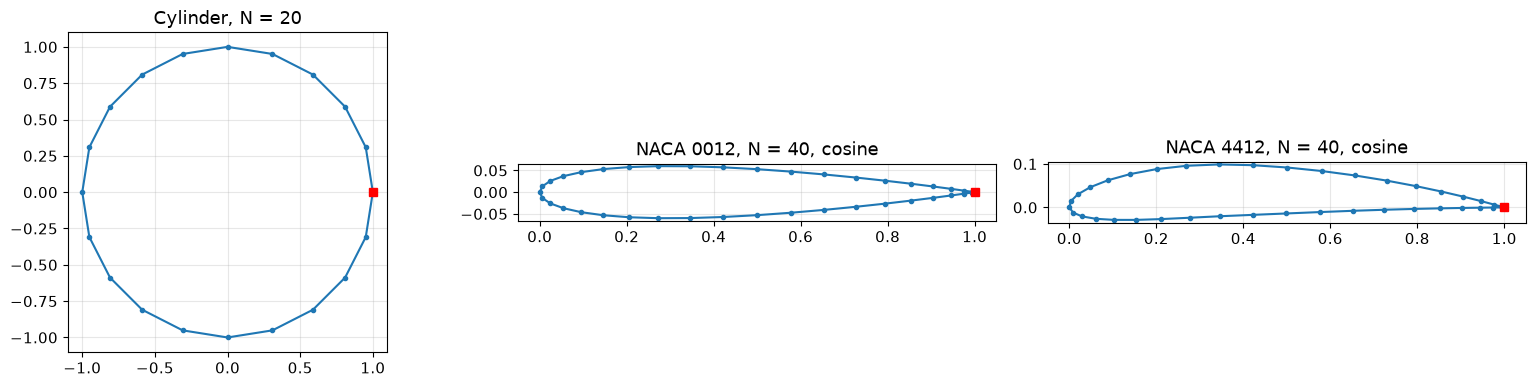

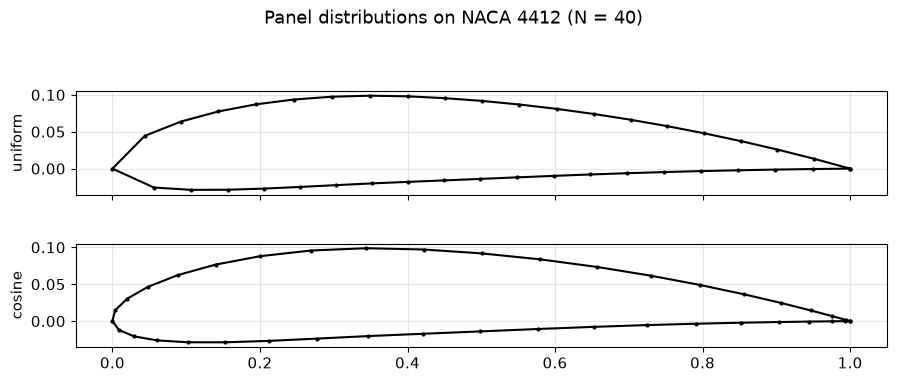

In [4]:
#plotting geometries
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (name, (xb, yb)) in zip(ax, {
        "Cylinder, N = 20": cylinder_geometry(20),
        "NACA 0012, N = 40, cosine": naca4_geometry("0012", 40),
        "NACA 4412, N = 40, cosine": naca4_geometry("4412", 40)}.items()):
    a.plot(xb, yb, "o-", ms=3); a.plot(xb[0], yb[0], "rs"); a.set_aspect("equal"); a.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
for a, sp in zip(ax, ["uniform", "cosine"]):
    xb, yb = naca4_geometry("4412", 40, sp)
    a.plot(xb, yb, "k.-", ms=4); a.set_aspect("equal"); a.set_ylabel(sp)
plt.suptitle("Panel distributions on NACA 4412 (N = 40)"); plt.tight_layout(); plt.show()